# PRIM — Stovepipe zero-mortality boundary by own-BN distance

Grid experiment: 7 bcas_rate × 3 own-BN distances × 100 seeds = 2,100 runs.
Stovepipe only. For each distance level, find the bcas_rate threshold where
T1 mortality transitions from 0 to >0 (PRIM density = 1).

In [10]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
from ema_workbench.analysis import prim

RESULTS = _root / "data_cluster" / "stove_bcas_distance_grid" / "20260708_140751_scenario_2btg_fixed_high_bcas" / "results.csv"
df = pd.read_csv(RESULTS)
print(f"Loaded {len(df)} runs")
print(f"Distances: {sorted(df['ccp_r1_same_bn_min'].unique())}")
print(f"BCAS rates: {sorted(df['bcas_rate'].unique())}")
print(f"Seeds: {df['seed'].nunique()}")

Loaded 2100 runs
Distances: [np.int64(10), np.int64(15), np.int64(20)]
BCAS rates: [np.float64(0.01), np.float64(0.02), np.float64(0.03), np.float64(0.04), np.float64(0.05), np.float64(0.06), np.float64(0.07)]
Seeds: 100


## Overview — mean T1 mortality by distance × bcas_rate

In [11]:
pivot = df.groupby(['ccp_r1_same_bn_min', 'bcas_rate'])['death_rate_T1_BCAS'].mean().unstack()
print(pivot.round(3).to_string())
print()
print("Fraction of seeds with zero T1 mortality:")
zero_frac = df.groupby(['ccp_r1_same_bn_min', 'bcas_rate'])['death_rate_T1_BCAS'].apply(lambda s: (s == 0).mean()).unstack()
print(zero_frac.round(3).to_string())

bcas_rate            0.01   0.02   0.03   0.04   0.05   0.06   0.07
ccp_r1_same_bn_min                                                 
10                  0.064  0.183  0.289  0.383  0.501  0.569  0.628
15                  0.268  0.461  0.533  0.580  0.654  0.699  0.751
20                  0.464  0.711  0.809  0.847  0.885  0.892  0.908

Fraction of seeds with zero T1 mortality:
bcas_rate           0.01  0.02  0.03  0.04  0.05  0.06  0.07
ccp_r1_same_bn_min                                          
10                  0.87  0.39  0.11   0.0   0.0   0.0   0.0
15                  0.48  0.06  0.02   0.0   0.0   0.0   0.0
20                  0.30  0.01  0.00   0.0   0.0   0.0   0.0


## PRIM per distance level

For each own-BN distance, run PRIM on `bcas_rate` to find the box where
`death_rate_T1_BCAS > 0` with density = 1.


Distance = 10 min
Cases with mortality > 0: 563 / 700 (80.4%)
coverage      0.710480
density       1.000000
id            3.000000
k           400.000000
mass          0.571429
mean          1.000000
n           400.000000
res_dim       1.000000
Name: 3, dtype: float64

           box 3                             
             min   max      qp value qp value
bcas_rate  0.035  0.07  1.459291e-38      NaN


Distance = 15 min
Cases with mortality > 0: 644 / 700 (92.0%)
coverage      0.621118
density       1.000000
id            3.000000
k           400.000000
mass          0.571429
mean          1.000000
n           400.000000
res_dim       1.000000
Name: 3, dtype: float64

           box 3                             
             min   max      qp value qp value
bcas_rate  0.035  0.07  3.274394e-15      NaN


Distance = 20 min
Cases with mortality > 0: 669 / 700 (95.6%)
coverage      0.747384
density       1.000000
id            2.000000
k           500.000000
mass          0.714286


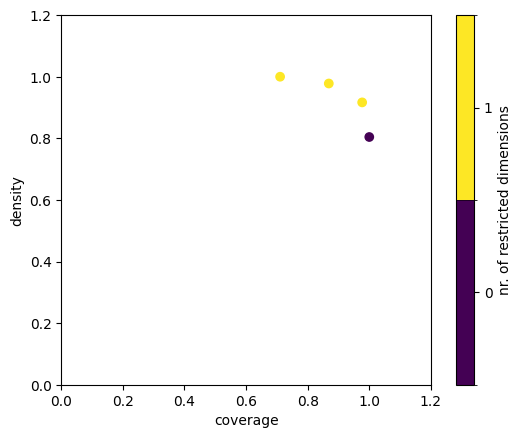

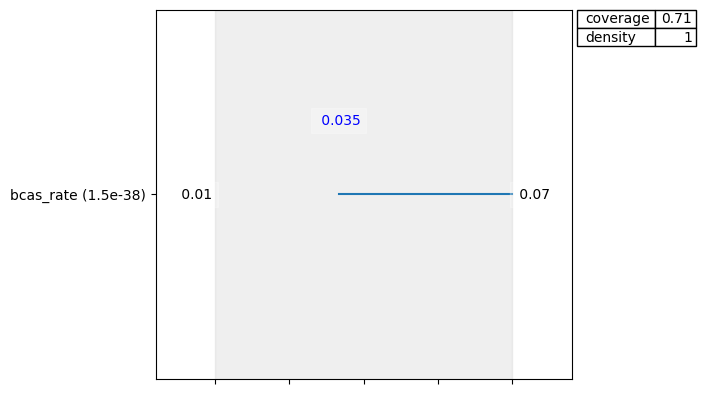

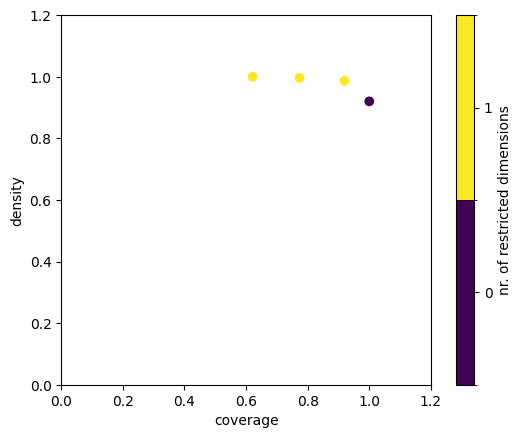

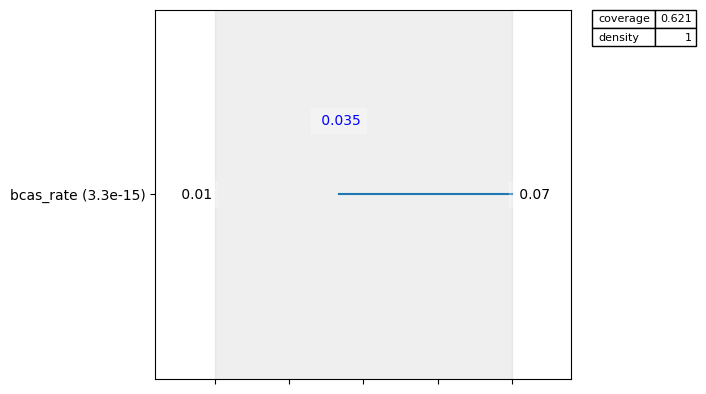

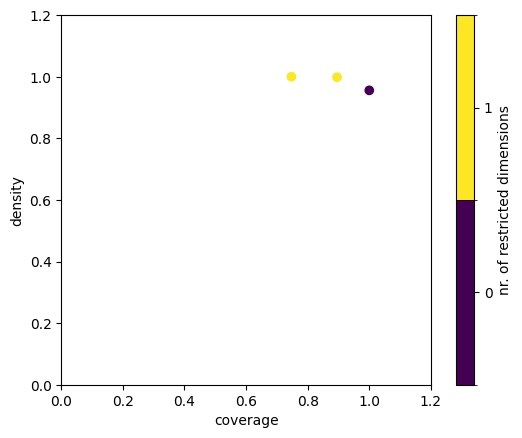

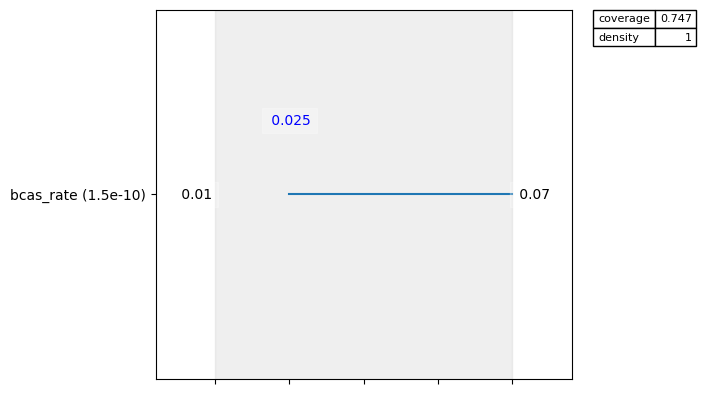

In [12]:
for dist in sorted(df['ccp_r1_same_bn_min'].unique()):
    sub = df[df['ccp_r1_same_bn_min'] == dist].copy()
    x = sub[['bcas_rate']].astype(float)
    y = sub['death_rate_T1_BCAS'].values > 0
    
    print(f"\n{'='*60}")
    print(f"Distance = {dist} min")
    print(f"Cases with mortality > 0: {y.sum()} / {len(y)} ({y.mean():.1%})")
    print(f"{'='*60}")
    
    p = prim.Prim(x, y, threshold=0.5)
    box = p.find_box()
    box.show_tradeoff()
    box.inspect(style='graph')
    box.inspect()

## Summary — bcas_rate threshold per distance

In [13]:
print(f"{'Distance':>10} {'bcas threshold':>15} {'% zero mort below':>20}")
print("-" * 50)
for dist in sorted(df['ccp_r1_same_bn_min'].unique()):
    sub = df[df['ccp_r1_same_bn_min'] == dist]
    for rate in sorted(df['bcas_rate'].unique()):
        subset = sub[sub['bcas_rate'] <= rate]
        zero_pct = (subset['death_rate_T1_BCAS'] == 0).mean()
        if zero_pct < 0.95:
            prev_rate = sorted(df['bcas_rate'].unique())[max(0, sorted(df['bcas_rate'].unique()).index(rate) - 1)]
            print(f"{dist:>10} {prev_rate:>15.2f} {zero_pct:>20.1%}")
            break
    else:
        print(f"{dist:>10} {'> 0.07':>15} {'100%':>20}")

  Distance  bcas threshold    % zero mort below
--------------------------------------------------
        10            0.01                87.0%
        15            0.01                48.0%
        20            0.01                30.0%
